# Classification with PyTorch v2 (oracle) — Response, deeper MLP

**Version:** 2nd Version (deeper MLP). **Role:** reference oracle for the v2 scratch twin.
Same data/features/splits/seed as v1; only the model and training change: `FC(22→64)→BN→ReLU→Dropout(0.2)→FC(64→64)→BN→(+residual)→ReLU→Dropout(0.2)→FC(64→1)`, 100 epochs, Adam + cosine schedule + weight decay. Weights → `./weights_v2/`.

In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
os.makedirs("weights_v2", exist_ok=True)
print("torch:", torch.__version__)

# ---- 1. LOAD DATA (identical to v1) ----
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = [
    "AcceptedCmp5", "AcceptedCmp3", "MntWines", "MntMeatProducts",
    "NumCatalogPurchases", "Recency", "Customer_Tenure_Days", "MntGoldProds",
    "Income", "MntFruits",
    "AcceptedCmp1", "AcceptedCmp2", "NumWebPurchases", "MntSweetProducts",
    "MntFishProducts", "NumStorePurchases", "Age",
]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

torch: 2.14.1+cu130
cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


## 2–3. Dataset Class + DataLoader (same 80/20 stratified split + scaler as v1)

In [2]:
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.asarray(X, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y, dtype=np.float32)).view(-1, 1)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return self.X[i], self.y[i]

X_temp, X_test, y_temp, y_test = train_test_split(
    X_full.values, y_full, test_size=0.20, random_state=SEED, stratify=y_full)
inc_idx = FEATURE_COLS.index("Income")
train_median = np.nanmedian(X_temp[:, inc_idx])
for arr in (X_temp, X_test):
    arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), train_median, arr[:, inc_idx])
scaler = StandardScaler().fit(X_temp)
Xtr, Xte = scaler.transform(X_temp), scaler.transform(X_test)
print(f"train {Xtr.shape} test {Xte.shape} | test pos rate {y_test.mean():.3f} | median fill {train_median:.0f}")
train_ds, test_ds = TabularDataset(Xtr, y_temp), TabularDataset(Xte, y_test)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True,
                            generator=torch.Generator().manual_seed(SEED))
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

train (1788, 22) test (448, 22) | test pos rate 0.150 | median fill 51651


## 4. Model Class v2 — ResNet-style block: FC→BN→ReLU→Drop → FC→BN→(+residual)→ReLU→Drop → FC

In [3]:
class ClfDeepMLP(nn.Module):
    def __init__(self, in_dim=22, h=64, p=0.2):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, h)
        self.bn1 = nn.BatchNorm1d(h)
        self.fc2 = nn.Linear(h, h)
        self.bn2 = nn.BatchNorm1d(h)
        self.fc3 = nn.Linear(h, 1)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(p)
        for fc, nl in ((self.fc1, "relu"), (self.fc2, "relu"), (self.fc3, "linear")):
            nn.init.kaiming_normal_(fc.weight, nonlinearity=nl)
            nn.init.zeros_(fc.bias)
    def forward(self, x):
        d1 = self.drop(self.relu(self.bn1(self.fc1(x))))
        s = self.bn2(self.fc2(d1)) + d1  # residual around the 64->64 block
        d2 = self.drop(self.relu(s))
        return self.fc3(d2)  # logits

device = torch.device("cpu")
model = ClfDeepMLP(in_dim=len(FEATURE_COLS)).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"params: {n_params} (expect ~5953)")
pos = (y_temp == 1).sum(); neg = (y_temp == 0).sum()
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos]))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)
print(f"pos_weight: {neg / pos:.3f} | epochs 100 | cosine schedule | wd 1e-4")

ClfDeepMLP(
  (fc1): Linear(in_features=22, out_features=64, bias=True)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=64, out_features=1, bias=True)
  (relu): ReLU()
  (drop): Dropout(p=0.2, inplace=False)
)
params: 5953 (expect ~5953)


pos_weight: 5.697 | epochs 100 | cosine schedule | wd 1e-4


## 5. Training Loop v2 (100 epochs) — logs train/val loss + val F1, saves to weights_v2

epoch 001 | train 1.0423 | val 0.6256 | acc 0.6830 | F1 0.4083 | lr 1.00e-03


epoch 010 | train 0.7065 | val 0.4466 | acc 0.7835 | F1 0.5126 | lr 9.76e-04


epoch 020 | train 0.6488 | val 0.4290 | acc 0.7857 | F1 0.5200 | lr 9.05e-04


epoch 030 | train 0.6303 | val 0.4196 | acc 0.7857 | F1 0.5294 | lr 7.94e-04


epoch 040 | train 0.5937 | val 0.3942 | acc 0.7879 | F1 0.5128 | lr 6.55e-04


...

epoch 060 | train 0.5612 | val 0.3942 | acc 0.7991 | F1 0.5408 | lr 3.45e-04


epoch 070 | train 0.5621 | val 0.3851 | acc 0.8103 | F1 0.5596 | lr 2.06e-04


epoch 080 | train 0.5563 | val 0.4036 | acc 0.7969 | F1 0.5427 | lr 9.55e-05


epoch 090 | train 0.5691 | val 0.3948 | acc 0.8036 | F1 0.5556 | lr 2.45e-05


epoch 100 | train 0.5470 | val 0.3966 | acc 0.7991 | F1 0.5455 | lr 0.00e+00
saved to weights_v2/


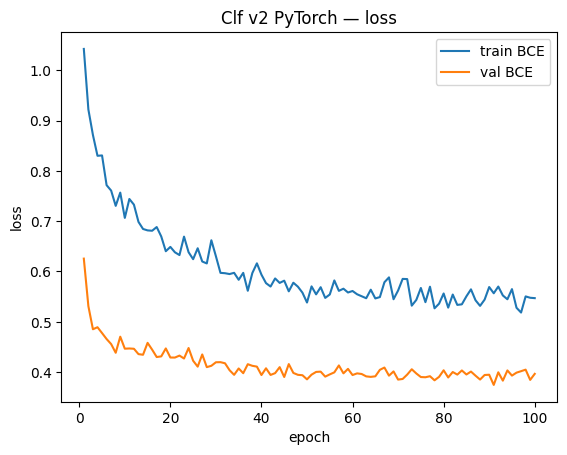

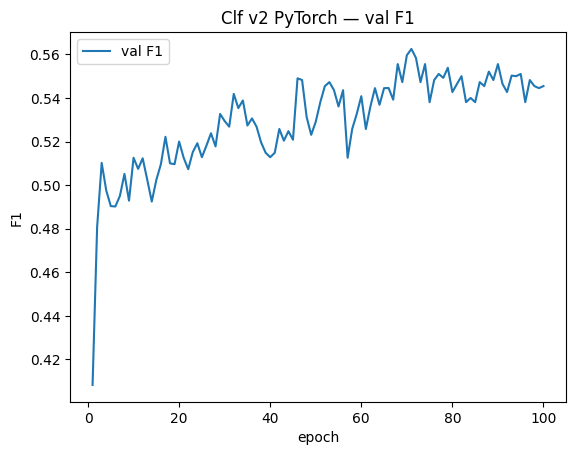

In [4]:
EPOCHS = 100
history = {"epoch": [], "train_loss": [], "val_loss": [], "val_acc": [], "val_f1": [], "lr": []}
bce = nn.BCEWithLogitsLoss()

def evaluate(m):
    m.eval()
    with torch.no_grad():
        Xt = torch.from_numpy(Xte.astype(np.float32)).to(device)
        yt = torch.from_numpy(y_test.astype(np.float32)).view(-1, 1).to(device)
        logits = m(Xt)
        loss = bce(logits, yt).item()
        prob = torch.sigmoid(logits).cpu().numpy().ravel()
        pred = (prob >= 0.5).astype(int)
        return loss, accuracy_score(y_test, pred), f1_score(y_test, pred)

for epoch in range(1, EPOCHS + 1):
    model.train()
    tot, n = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
    scheduler.step()
    with torch.no_grad():
        tot = sum(criterion(model(xb.to(device)), yb.to(device)).item() * len(xb) for xb, yb in train_loader)
        n = len(train_ds)
    vl, va, vf = evaluate(model)
    lr = optimizer.param_groups[0]["lr"]
    history["epoch"].append(epoch)
    history["train_loss"].append(tot / n)
    history["val_loss"].append(vl)
    history["val_acc"].append(va)
    history["val_f1"].append(vf)
    history["lr"].append(lr)
    if epoch == 1 or epoch % 10 == 0 or epoch == EPOCHS:
        print(f"epoch {epoch:03d} | train {tot/n:.4f} | val {vl:.4f} | acc {va:.4f} | F1 {vf:.4f} | lr {lr:.2e}")

torch.save(model.state_dict(), "weights_v2/classification_mlp.pt")
np.savez("weights_v2/classification_scaler.npz", mean=scaler.mean_, scale=scaler.scale_,
         columns=np.array(FEATURE_COLS), train_median=np.array([train_median]))
pd.DataFrame(history).to_csv("weights_v2/classification_pytorch_history.csv", index=False)
print("saved to weights_v2/")
plt.figure(); plt.plot(history["epoch"], history["train_loss"], label="train BCE")
plt.plot(history["epoch"], history["val_loss"], label="val BCE")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Clf v2 PyTorch — loss"); plt.savefig("media/loss_clf_v2.png", dpi=150); plt.show()
plt.figure(); plt.plot(history["epoch"], history["val_f1"], label="val F1")
plt.xlabel("epoch"); plt.ylabel("F1"); plt.legend(); plt.title("Clf v2 PyTorch — val F1"); plt.show()

## 6. Inference Loop — fresh instance loads `./weights_v2/classification_mlp.pt`

In [5]:
fresh = ClfDeepMLP(in_dim=len(FEATURE_COLS)).to(device)
fresh.load_state_dict(torch.load("weights_v2/classification_mlp.pt", map_location=device))
fresh.eval()
with torch.no_grad():
    Xt = torch.from_numpy(Xte.astype(np.float32)).to(device)
    prob = torch.sigmoid(fresh(Xt)).cpu().numpy().ravel()
pred = (prob >= 0.5).astype(int)
test_bce = float(bce(fresh(Xt), torch.from_numpy(y_test.astype(np.float32)).view(-1,1).to(device)).item())
metrics = {
    "test_loss_BCE": round(test_bce, 4),
    "accuracy": round(float(accuracy_score(y_test, pred)), 4),
    "precision": round(float(precision_score(y_test, pred, zero_division=0)), 4),
    "recall": round(float(recall_score(y_test, pred, zero_division=0)), 4),
    "f1": round(float(f1_score(y_test, pred, zero_division=0)), 4),
    "roc_auc": round(float(roc_auc_score(y_test, prob)), 4),
    "n_test": int(len(y_test)), "seed": SEED,
}
print(json.dumps(metrics, indent=2))
with open("weights_v2/classification_pytorch_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
for i in range(5):
    print(f"  prob={prob[i]:.3f} pred={pred[i]} true={int(y_test[i])}")

{
  "test_loss_BCE": 0.3966,
  "accuracy": 0.7991,
  "precision": 0.4122,
  "recall": 0.806,
  "f1": 0.5455,
  "roc_auc": 0.8818,
  "n_test": 448,
  "seed": 42
}
  prob=0.041 pred=0 true=0
  prob=0.000 pred=0 true=0
  prob=0.021 pred=0 true=0
  prob=0.273 pred=0 true=0
  prob=0.039 pred=0 true=0


## Architecture graph (ONNX — source of the REPORT.md image)
One call to the shared `onnx_viz.save_graph` helper exports the trained oracle above to `media/arch_clf_v2.onnx`
(open it in Netron to inspect) and renders `media/arch_clf_v2.png` (input → … → output).

In [6]:
from onnx_viz import save_graph
save_graph(fresh, "arch_clf_v2", 22)


rendered media/arch_clf_v2.png from media/arch_clf_v2.onnx


'media/arch_clf_v2.onnx'